# Week 4 - Part F (bonus): is the seasonality growing, or is the business?

Week 1 Task 5 left this open on `flights.csv`: the seasonal swing gets bigger every year, so is the seasonality itself growing, or is it just the airline growing? Here I settle it on real data I found myself.

**Data:** Australia's Pharmaceutical Benefits Scheme (PBS), monthly scripts and cost by drug class (ATC codes), July 1991 - June 2008. Collected by Medicare Australia, published in Rob Hyndman's `tsibbledata` R package (tidyverts) as `PBS.rda`: https://raw.githubusercontent.com/tidyverts/tsibbledata/master/data/PBS.rda, downloaded 17 October 2026. `get_data.py` re-creates the CSV from that file. This is real data, not course data.

The category column is the ATC level-2 drug class. I take the 13 classes under "A - Alimentary tract and metabolism" and focus on **A10, drugs used in diabetes**, the class with the clearest growth and a strong yearly cycle (Australian scripts spike in December/January, when patients stock up before the PBS safety-net threshold resets).

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from statsmodels.tsa.seasonal import seasonal_decompose

try:
    HERE = Path(__file__).resolve().parent
    IN_NOTEBOOK = False
except NameError:
    HERE = Path.cwd()
    IN_NOTEBOOK = True
sys.path.insert(0, str(HERE.parent))          # tslib / vizlib live in week4/

import tslib
from vizlib import PALETTE, style_defaults

style_defaults()
BLUE, ORANGE, GREEN = PALETTE["series"]
GREY, INK, SOFT = PALETTE["muted"], PALETTE["ink"], PALETTE["ink_soft"]

def show():
    if IN_NOTEBOOK:
        plt.show()
    else:
        plt.close("all")

## 1. Load and audit

In [2]:
pbs = pd.read_csv(HERE / "data" / "pbs_alimentary_monthly.csv")
pbs["month"] = pd.to_datetime(pbs.month, format="%Y-%m")
print(pbs.shape, "| categories:", pbs.atc2.nunique())
print(pbs.groupby(["atc2", "atc2_desc"]).month.agg(["min", "max", "count"]).to_string())

(2544, 5) | categories: 13
                                                            min        max  count
atc2 atc2_desc                                                                   
A01  STOMATOLOGICAL PREPARATIONS                     1991-07-01 2008-06-01    204
A02  DRUGS FOR ACID RELATED DISORDERS                1991-07-01 2008-06-01    204
A03  DRUGS FOR FUNCTIONAL GASTROINTESTINAL DISORDERS 1991-07-01 2008-06-01    204
A04  ANTIEMETICS AND ANTINAUSEANTS                   1991-07-01 2008-06-01    204
A05  BILE AND LIVER THERAPY                          2000-07-01 2008-06-01     96
A06  LAXATIVES                                       1991-07-01 2008-06-01    204
A07  ANTIDIARR ,INTEST  ANTIINFL /ANTIINFECT  AGENTS 1991-07-01 2008-06-01    204
A09  DIGESTIVES, INCL ENZYMES                        1991-07-01 2008-06-01    204
A10  ANTIDIABETIC THERAPY                            1991-07-01 2008-06-01    204
A11  VITAMINS                                        1991-07-01 2008-06

In [3]:
print("duplicate (month, atc2) rows:", pbs.duplicated(["month", "atc2"]).sum())
a10 = pbs[pbs.atc2 == "A10"].set_index("month").sort_index()
cost = (a10.cost_aud / 1e6).rename("cost_aud_m")
audit = tslib.audit_index(cost, "MS")
print(audit)
print("negative or zero costs:", int((cost <= 0).sum()))

duplicate (month, atc2) rows: 0
{'dtype_ok': True, 'monotonic': True, 'n_rows': 204, 'n_duplicated': 0, 'n_missing': 0, 'missing_dates': [], 'span': ('1991-07-01 00:00:00', '2008-06-01 00:00:00'), 'partial_tail': True, 'tail_period': '2008', 'tail_count': 6}
negative or zero costs: 0


**Audit findings.** The A10 index is a clean, sorted monthly `DatetimeIndex`: 204 months, no duplicates, no missing months, no zero or negative values. Two things to note:
- `partial_tail` is True: 2008 only has January-June, and 1991 only July-December. Neither is a problem for a monthly decomposition, but **no yearly totals** can be compared for 1991 or 2008.
- Across the category column, A05 (bile and liver therapy) only has 96 of 204 months, so it can't be compared over the full span. That doesn't affect A10.

## 2. The three panels

In [4]:
add = seasonal_decompose(cost, model="additive", period=12)
mul = seasonal_decompose(cost, model="multiplicative", period=12)
res_add = add.resid.dropna()
res_mul = (mul.resid.dropna() - 1) * 100            # % deviation from trend x seasonal
half = len(res_add) // 2
sd_add = (res_add.iloc[:half].std(), res_add.iloc[half:].std())
sd_mul = (res_mul.iloc[:half].std(), res_mul.iloc[half:].std())
split = res_add.index[half]
yr = cost[(cost.index.year >= 1992) & (cost.index.year <= 2007)]
swing = yr.groupby(yr.index.year).agg(lambda x: x.max() - x.min())
level = yr.groupby(yr.index.year).mean()
print(f"additive residual SD:       {sd_add[0]:.2f} -> {sd_add[1]:.2f} AUD m  (x{sd_add[1] / sd_add[0]:.2f}), split at {split:%b %Y}")
print(f"multiplicative residual SD: {sd_mul[0]:.2f}% -> {sd_mul[1]:.2f}%  (x{sd_mul[1] / sd_mul[0]:.2f})")
print(f"within-year swing: {swing.iloc[0]:.1f}m (1992) -> {swing.iloc[-1]:.1f}m (2007), x{swing.iloc[-1] / swing.iloc[0]:.1f}")
print(f"swing / yearly mean: {(swing / level).iloc[0]:.2f} (1992) -> {(swing / level).iloc[-1]:.2f} (2007); range {(swing / level).min():.2f}-{(swing / level).max():.2f}")
print(f"multiplicative seasonal factors: Jan {mul.seasonal.iloc[6]:.2f}, Feb {mul.seasonal.iloc[7]:.2f}, Dec {mul.seasonal.iloc[5]:.2f}")

bank_w = 13.0
bank = tslib.banked_figsize(cost.to_numpy(), width=bank_w)
print(f"banked_figsize(width={bank_w}) -> height {bank[1]:.2f} in, aspect h/w = {bank[1] / bank[0]:.2f}")

additive residual SD:       0.70 -> 1.08 AUD m  (x1.55), split at Jan 2000
multiplicative residual SD: 4.92% -> 4.79%  (x0.97)
within-year swing: 3.0m (1992) -> 11.6m (2007), x3.9
swing / yearly mean: 0.79 (1992) -> 0.52 (2007); range 0.45-0.81
multiplicative seasonal factors: Jan 1.33, Feb 0.78, Dec 1.23
banked_figsize(width=13.0) -> height 2.52 in, aspect h/w = 0.19


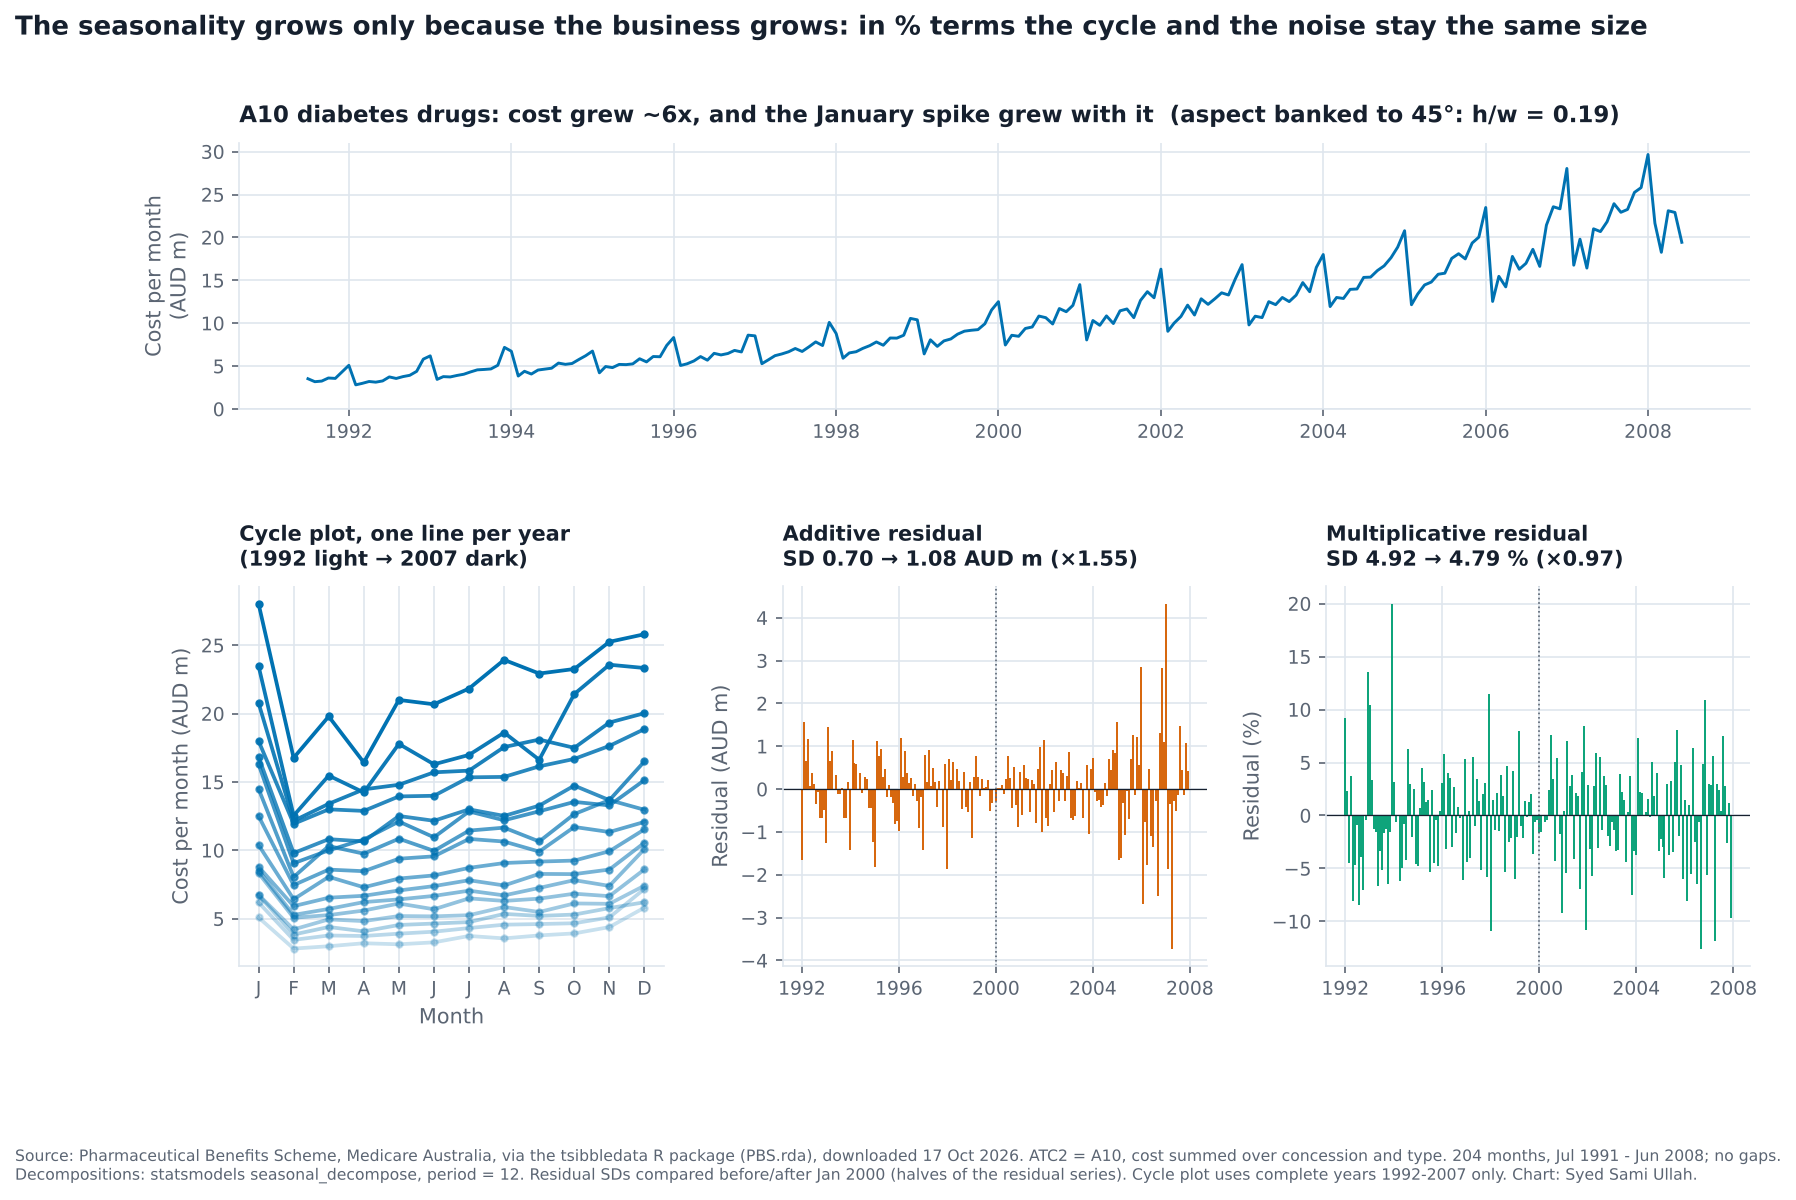

In [5]:
fig = plt.figure(figsize=(bank_w, bank[1] + 4.6))
gs = fig.add_gridspec(2, 3, height_ratios=[bank[1], 3.6], hspace=0.55, wspace=0.28)
ax1 = fig.add_subplot(gs[0, :])
ax2 = fig.add_subplot(gs[1, 0])
ax3 = fig.add_subplot(gs[1, 1])
ax4 = fig.add_subplot(gs[1, 2], sharex=ax3)

ax1.plot(cost.index, cost, color=BLUE, lw=1.4)
ax1.set_ylabel("Cost per month\n(AUD m)")
ax1.set_ylim(0, None)
ax1.xaxis.set_major_locator(mdates.YearLocator(2))
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax1.set_title(f"A10 diabetes drugs: cost grew ~6x, and the January spike grew with it  "
              f"(aspect banked to 45°: h/w = {bank[1] / bank[0]:.2f})", fontsize=11)

tslib.cycle_plot(ax2, cost[(cost.index.year >= 1992) & (cost.index.year <= 2007)], by="month", color=BLUE)
ax2.set_xticklabels(list("JFMAMJJASOND"))
ax2.set_ylabel("Cost per month (AUD m)")
ax2.set_title("Cycle plot, one line per year\n(1992 light → 2007 dark)", fontsize=10)

for ax, r, sd, unit, col, name in [(ax3, res_add, sd_add, "AUD m", ORANGE, "Additive residual"),
                                   (ax4, res_mul, sd_mul, "%", GREEN, "Multiplicative residual")]:
    ax.vlines(r.index, 0, r, color=col, lw=0.9)
    ax.axvline(split, color=SOFT, lw=0.8, ls=":")
    ax.axhline(0, color=INK, lw=0.6)
    ax.set_ylabel(f"Residual ({unit})")
    ax.set_title(f"{name}\nSD {sd[0]:.2f} → {sd[1]:.2f} {unit} (×{sd[1] / sd[0]:.2f})", fontsize=10)
    ax.xaxis.set_major_locator(mdates.YearLocator(4))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

fig.suptitle("The seasonality grows only because the business grows: in % terms the cycle and the noise stay the same size",
             x=0.01, y=1.0, ha="left", fontweight="bold", fontsize=12.5)
fig.text(0.01, -0.06, "Source: Pharmaceutical Benefits Scheme, Medicare Australia, via the tsibbledata R package (PBS.rda), downloaded 17 Oct 2026. "
         "ATC2 = A10, cost summed over concession and type. 204 months, Jul 1991 - Jun 2008; no gaps.\n"
         "Decompositions: statsmodels seasonal_decompose, period = 12. Residual SDs compared before/after "
         f"{split:%b %Y} (halves of the residual series). Cycle plot uses complete years 1992-2007 only. Chart: Syed Sami Ullah.",
         fontsize=7.5, color=SOFT, va="top")
fig.savefig(HERE / "partF_cycle.png", dpi=300, bbox_inches="tight", facecolor="white")
show()

**What this chart shows.** The cycle plot's lines keep the same shape (January high, February low) while every line sits higher than the year before, so the swing grows with the level. The additive residuals fan out over time, which is the classic sign of a wrong additive model, while the multiplicative residuals stay the same width from start to end.

## 3. The answer

**The seasonality is not growing on its own, the business is.** The within-year swing rose from 3.0m to 11.6m AUD (×3.9) between 1992 and 2007, but as a share of each year's average it stayed between about 0.45 and 0.8 with no upward drift, and the multiplicative residual SD barely changes between the two halves (4.9% → 4.8%, ×0.97) while the additive one grows ×1.55.

That's the same answer the textbook gives for `flights.csv` (multiplicative seasonality), so here the data agrees with the textbook.